In [8]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [9]:
import transition_prior as tp

import matplotlib.pyplot as plt
def plot_heatmap(matrix):
    plt.imshow(matrix, cmap='binary')
    plt.colorbar()
    plt.xlabel("to")
    plt.ylabel("from")
    plt.show()

ModuleNotFoundError: No module named 'transition_prior'

In [10]:
uninf = tp.TransitionPrior(10)
uninf.offset(1)
buninf = uninf.get_beta()
plot_heatmap(buninf)

NameError: name 'plot_heatmap' is not defined

In [7]:
beta = tp.TransitionPrior(10)
beta.prefer_small_intervals(10,1)
beta.prefer_low_register(10,2,2)
beta.penalize_repeated_notes(0.5)
beta.prefer_lower_pitches(5)
beta.offset(1)
b = beta.get_beta()
plot_heatmap(b)


NameError: name 'plot_heatmap' is not defined

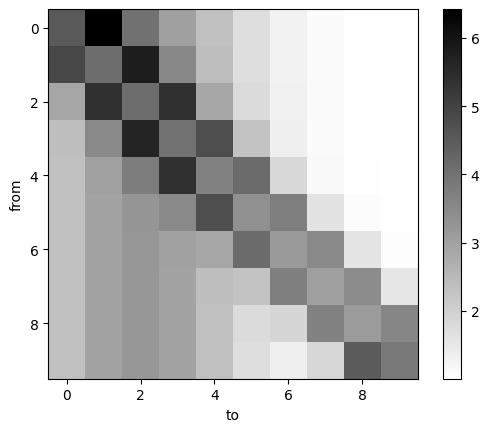

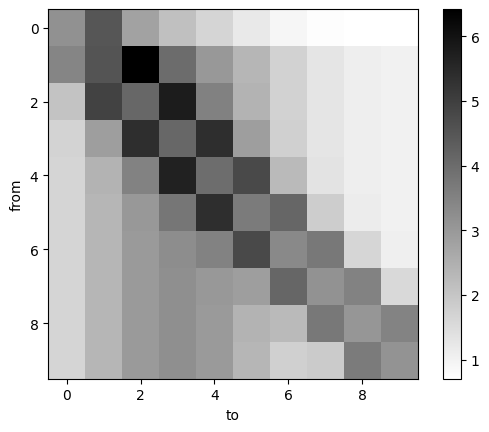

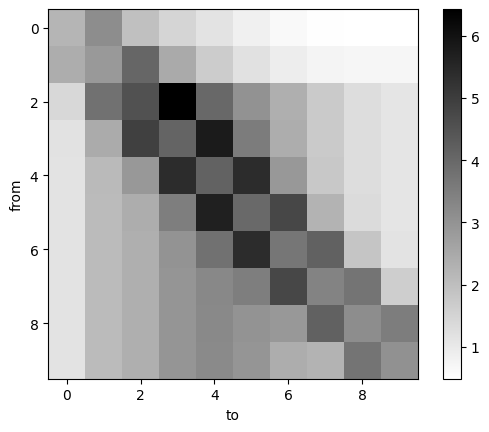

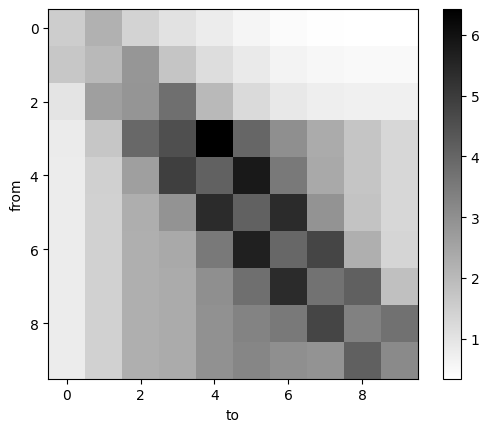

In [15]:
import numpy as np

def shift_and_cut(beta: np.ndarray, shift: int = 1, scale_func=lambda d: 0.7**d) -> np.ndarray:
    V = beta.shape[0]
    new_beta = np.zeros((V, V), dtype=float)
    i, j = np.ogrid[:V, :V]
    if shift > 0:
        new_beta[shift:, shift:] = beta[:-shift, :-shift]
        dist = np.maximum(shift - i, shift - j).clip(min=0)
        mask = (i < shift) | (j < shift)
    elif shift < 0:
        s = V + shift
        new_beta[:shift, :shift] = beta[-shift:, -shift:]
        dist = np.maximum(i - (s - 1), j - (s - 1)).clip(min=0)
        mask = (i >= s) | (j >= s)
    else:
        return beta.copy()
    new_beta[mask] = (beta * scale_func(dist))[mask]
    return new_beta

for n in range(4):
    b1 = shift_and_cut(b, n)
    u.plot_heatmap(b1)

array([[0, 1, 2],
       [3, 4, 5],
       [6, 7, 8]])

array([[6, 7, 8],
       [0, 1, 2],
       [3, 4, 5]])